# 从零实现 Teacher–Student 知识蒸馏

本 Notebook 基于 PyTorch、Qwen3 和 Hugging Face TRL，
从零学习并实现 Teacher–Student 知识蒸馏（Knowledge Distillation，KD）。

主要包括知识蒸馏原理、Softmax 与 KL 散度、Teacher/Student 模型加载、
Off-policy 与 On-policy 蒸馏、GKDTrainer 训练及模型评估。

实验中使用 Qwen3-4B 作为 Teacher，Qwen3-0.6B 作为 Student，
逐步理解大模型如何通过概率分布指导小模型学习。

## 1. Teacher–Student 知识蒸馏原理

Teacher–Student 知识蒸馏（Knowledge Distillation，KD）是一种利用能力较强的教师模型（Teacher Model）指导较小的学生模型（Student Model）进行训练的技术，其核心思想是让学生模型学习教师模型的预测行为，从而以更少的模型参数获得部分教师模型的能力。与传统 SFT 使用真实 Token 作为硬标签（Hard Label）不同，知识蒸馏通过教师模型输出的 Logits，经 Softmax 转换得到整个词表的概率分布，作为软标签（Soft Label）指导学生学习。训练时，Teacher 和 Student 接收相同的上下文，分别计算预测概率，并通过 KL 散度或 JSD 等损失函数衡量两者的分布差异，随后进行反向传播，冻结 Teacher 的参数，只更新 Student 的参数，使学生的预测分布逐渐接近教师。本实验采用 Qwen3-4B 作为 Teacher、Qwen3-0.6B 作为 Student，并逐步学习 Off-policy、On-policy 以及 GKD（Generalized Knowledge Distillation）等蒸馏方法。

## 2. Softmax、KL 散度与蒸馏 Loss

In [1]:
# 从 Logits 到概率分布

import torch
import torch.nn.functional as F

# 假设词表只有三个 Token
vocab = ["北京", "上海", "广州"]

# Teacher 和 Student 的原始预测分数
teacher_logits = torch.tensor([4.0, 2.0, 1.0])
student_logits = torch.tensor([1.5, 2.0, 1.0])

# 使用 Softmax 转换为概率分布
teacher_probs = F.softmax(teacher_logits, dim=-1)
student_probs = F.softmax(student_logits, dim=-1)

print("Teacher 概率分布:", teacher_probs)
print("Student 概率分布:", student_probs)

print("\n各 Token 的预测概率：")
for token, p_teacher, p_student in zip(
    vocab, teacher_probs, student_probs
):
    print(
        f"{token}: "
        f"Teacher={p_teacher.item():.4f}, "
        f"Student={p_student.item():.4f}"
    )

print("\nTeacher 概率总和:", teacher_probs.sum().item())
print("Student 概率总和:", student_probs.sum().item())

Teacher 概率分布: tensor([0.8438, 0.1142, 0.0420])
Student 概率分布: tensor([0.3072, 0.5065, 0.1863])

各 Token 的预测概率：
北京: Teacher=0.8438, Student=0.3072
上海: Teacher=0.1142, Student=0.5065
广州: Teacher=0.0420, Student=0.1863

Teacher 概率总和: 0.9999999403953552
Student 概率总和: 1.0


In [2]:
# 手动计算 Teacher 与 Student 的 KL 散度

# 复用前面得到的概率分布
p = teacher_probs
q = student_probs

# Forward KL：D_KL(P || Q)
kl_loss_manual = torch.sum(
    p * torch.log(p / q)
)

print("手动计算 KL Loss:", kl_loss_manual.item())

# 使用 PyTorch 自带的 KL 散度函数验证
kl_loss_torch = F.kl_div(
    torch.log(q),
    p,
    reduction="sum"
)

print("PyTorch KL Loss:", kl_loss_torch.item())

# 验证两种计算方式一致
assert torch.allclose(
    kl_loss_manual,
    kl_loss_torch,
    atol=1e-6
)

print("KL Loss 计算验证通过！")

手动计算 KL Loss: 0.6199103593826294
PyTorch KL Loss: 0.6199103593826294
KL Loss 计算验证通过！


In [3]:
# 验证两个完全相同的概率分布

same_probs = teacher_probs.clone()

kl_same = F.kl_div(
    torch.log(same_probs),
    teacher_probs,
    reduction="sum"
)

print("相同分布的 KL Loss:", kl_same.item())

相同分布的 KL Loss: 0.0


In [4]:
# 使用梯度下降实现最简单的知识蒸馏

import torch
import torch.nn.functional as F

# Teacher 的 Logits：固定不变
teacher_logits = torch.tensor([4.0, 2.0, 1.0])

# Student 的 Logits：需要通过训练更新
student_logits = torch.nn.Parameter(
    torch.tensor([1.5, 2.0, 1.0])
)

# Teacher 提供软标签
teacher_probs = F.softmax(teacher_logits, dim=-1)

# 优化器只更新 Student
optimizer = torch.optim.SGD(
    [student_logits],
    lr=0.5
)

loss_history = []

# 训练 60 步
for step in range(60):

    # 1. Student 计算预测分布
    student_log_probs = F.log_softmax(
        student_logits,
        dim=-1
    )

    # 2. 计算 Forward KL
    loss = F.kl_div(
        student_log_probs,
        teacher_probs,
        reduction="sum"
    )

    # 3. 反向传播
    optimizer.zero_grad()
    loss.backward()

    # 4. 更新 Student Logits
    optimizer.step()

    loss_history.append(loss.item())

    if step % 10 == 0 or step == 59:
        print(
            f"Step {step + 1:02d} | "
            f"KL Loss: {loss.item():.6f}"
        )

Step 01 | KL Loss: 0.619910
Step 11 | KL Loss: 0.022999
Step 21 | KL Loss: 0.003783
Step 31 | KL Loss: 0.001387
Step 41 | KL Loss: 0.000686
Step 51 | KL Loss: 0.000367
Step 60 | KL Loss: 0.000213


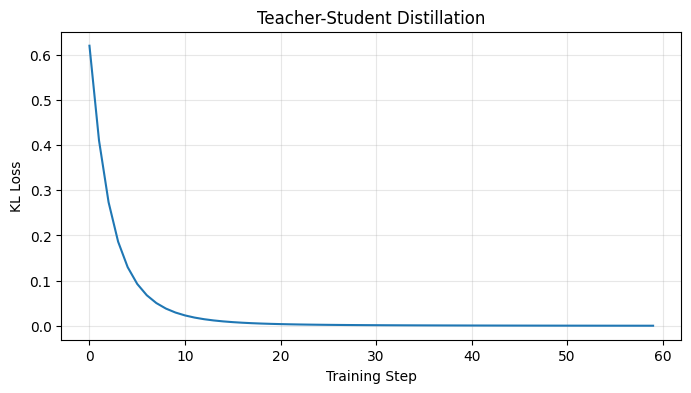

In [5]:
# 可视化蒸馏训练过程

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.xlabel("Training Step")
plt.ylabel("KL Loss")
plt.title("Teacher-Student Distillation")

plt.grid(alpha=0.3)
plt.show()

## 3. 蒸馏数据集加载与分析

### 认识蒸馏数据集

本实验使用 Hugging Face 上的 `sergiopaniego/pi-mono-chat` 数据集，该数据集由 pi-mono Agent Session 转换而来，主要包含用户与 AI 助手之间的对话记录。数据采用 `messages` 格式组织，每条样本可以包含多轮对话，常见字段为 `role`（消息角色）和 `content`（消息内容）。

与之前的 SFT 类似，知识蒸馏也需要区分 **Prompt（输入上下文）** 和 **Completion（目标续写）**。但两者的监督方式不同：SFT 使用真实 Token 作为硬标签，通过交叉熵损失训练模型；而本实验首先学习的 **Off-policy 知识蒸馏** 使用数据集中已有的续写轨迹，让 Teacher 和 Student 在相同的预测位置分别计算 Token 概率分布，再通过 KL 散度等损失函数指导 Student 学习。

本节首先加载真实数据集，检查 `messages` 结构和消息角色，再分析哪些内容作为 Prompt、哪些内容作为 Completion，为后续 Tokenization 和蒸馏训练做好准备。

In [ ]:
# 加载并保存真实的蒸馏数据集

from pathlib import Path
from datasets import load_dataset, load_from_disk

DATASET_ID = "sergiopaniego/pi-mono-chat"
DATA_DIR = Path("./distillation-data/pi-mono-chat")

if DATA_DIR.exists():
    # 本地已有数据，直接读取
    print(f"从本地加载数据集：{DATA_DIR}")
    raw_dataset = load_from_disk(str(DATA_DIR))
else:
    # 首次运行：从 Hugging Face 下载
    print(f"从 Hugging Face 下载数据集：{DATASET_ID}")
    raw_dataset = load_dataset(DATASET_ID)

    # 保存完整数据集到本地
    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    raw_dataset.save_to_disk(str(DATA_DIR))

    print(f"数据集已保存到：{DATA_DIR.resolve()}")

print("\n数据集信息：")
print(raw_dataset)

从本地加载数据集：disttillation-data/pi-mono-chat

数据集信息：
DatasetDict({
    train: Dataset({
        features: ['messages'],
        num_rows: 797
    })
    test: Dataset({
        features: ['messages'],
        num_rows: 89
    })
})


In [7]:
# 查看第一条真实训练样本

import json

train_ds = raw_dataset["train"]
eval_ds = raw_dataset["test"]

print("训练集大小:", len(train_ds))
print("测试集大小:", len(eval_ds))

print("\n数据集字段:")
print(train_ds.column_names)

print("\n第一条训练样本:")
print(
    json.dumps(
        train_ds[0],
        ensure_ascii=False,
        indent=2
    )
)

训练集大小: 797
测试集大小: 89

数据集字段:
['messages']

第一条训练样本:
{
  "messages": [
    {
      "content": "do 1",
      "role": "user"
    },
    {
      "content": "Exposing `authStorage` on the harness and moving the text helpers over to `harness.ts`.",
      "role": "assistant"
    }
  ]
}


In [8]:
# 统计消息角色和对话长度

from collections import Counter

role_counter = Counter()
message_lengths = []

for sample in train_ds:

    messages = sample["messages"]

    message_lengths.append(len(messages))

    for message in messages:
        role_counter[message["role"]] += 1

print("各角色消息数量:")
for role, count in role_counter.items():
    print(f"{role}: {count}")

print("\n每条样本的消息数量:")
print("最少:", min(message_lengths))
print("最多:", max(message_lengths))
print("平均:", sum(message_lengths) / len(message_lengths))

各角色消息数量:
user: 797
assistant: 797

每条样本的消息数量:
最少: 2
最多: 2
平均: 2.0


In [9]:
# 从真实数据中提取 Prompt 和 Completion

sample = train_ds[0]
messages = sample["messages"]

# 取出 User 消息作为 Prompt
prompt_messages = messages[:-1]

# 取出最后一条 Assistant 消息作为 Completion
completion_message = messages[-1]

print("Prompt:")
print(prompt_messages)

print("\nCompletion:")
print(completion_message)

Prompt:
[{'content': 'do 1', 'role': 'user'}]

Completion:
{'content': 'Exposing `authStorage` on the harness and moving the text helpers over to `harness.ts`.', 'role': 'assistant'}


In [10]:
# 检查 Prompt 和 Completion 的基本有效性

def validate_samples(dataset):
    valid_count = 0

    for sample in dataset:
        messages = sample["messages"]

        assert len(messages) == 2
        assert messages[0]["role"] == "user"
        assert messages[1]["role"] == "assistant"

        prompt = messages[0]["content"]
        completion = messages[1]["content"]

        assert isinstance(prompt, str)
        assert isinstance(completion, str)

        # 确保不是空字符串
        assert prompt.strip()
        assert completion.strip()

        valid_count += 1

    return valid_count


print("训练集有效样本数:", validate_samples(train_ds))
print("测试集有效样本数:", validate_samples(eval_ds))

训练集有效样本数: 797
测试集有效样本数: 89


## 4. Tokenizer 与 Chat Template

In [11]:
# 加载 Teacher 和 Student 的 Tokenizer

from transformers import AutoTokenizer, AutoConfig

TEACHER_ID = "Qwen/Qwen3-4B"
STUDENT_ID = "Qwen/Qwen3-0.6B"

# 加载 Tokenizer
teacher_tokenizer = AutoTokenizer.from_pretrained(
    TEACHER_ID,
    padding_side="left"
)

student_tokenizer = AutoTokenizer.from_pretrained(
    STUDENT_ID,
    padding_side="left"
)

# 加载模型配置（不加载权重）
teacher_config = AutoConfig.from_pretrained(TEACHER_ID)
student_config = AutoConfig.from_pretrained(STUDENT_ID)

print("Teacher:", TEACHER_ID)
print("Student:", STUDENT_ID)

print("\nTeacher vocab_size:", teacher_config.vocab_size)
print("Student vocab_size:", student_config.vocab_size)

print("\nTeacher tokenizer 长度:", len(teacher_tokenizer))
print("Student tokenizer 长度:", len(student_tokenizer))

Teacher: Qwen/Qwen3-4B
Student: Qwen/Qwen3-0.6B

Teacher vocab_size: 151936
Student vocab_size: 151936

Teacher tokenizer 长度: 151669
Student tokenizer 长度: 151669


In [12]:
# 检查 Teacher 和 Student 的词表是否一致

# 1. 检查模型输出词表大小
same_vocab_size = (
    teacher_config.vocab_size
    == student_config.vocab_size
)

# 2. 检查完整 Token → ID 映射
same_vocab_mapping = (
    teacher_tokenizer.get_vocab()
    == student_tokenizer.get_vocab()
)

print("模型 vocab_size 是否一致:", same_vocab_size)
print("Token → ID 映射是否一致:", same_vocab_mapping)

# 3. 验证是否满足白盒 Logits 蒸馏的基本条件
assert same_vocab_size, "Teacher 和 Student 的词表大小不一致！"

assert same_vocab_mapping, "Teacher 和 Student 的 Token ID 映射不一致！"

print("\nTokenizer 词表对齐检查通过！")

模型 vocab_size 是否一致: True
Token → ID 映射是否一致: True

Tokenizer 词表对齐检查通过！


In [13]:
# 使用 Chat Template 渲染真实对话

# 读取第一条真实训练样本
sample = train_ds[0]
messages = sample["messages"]

# 渲染完整对话（User + Assistant）
full_text = student_tokenizer.apply_chat_template(
    messages,
    tokenize=False,  # 先返回字符串，而不是token ids
    add_generation_prompt=False,  # 不额外添加等待生成的assistant开头
    enable_thinking=False  # 使用非思考模式的聊天模版
)

print("原始 messages:")
print(messages)

print("\nChat Template 渲染结果:")
print(full_text)

原始 messages:
[{'content': 'do 1', 'role': 'user'}, {'content': 'Exposing `authStorage` on the harness and moving the text helpers over to `harness.ts`.', 'role': 'assistant'}]

Chat Template 渲染结果:
<|im_start|>user
do 1<|im_end|>
<|im_start|>assistant
<think>

</think>

Exposing `authStorage` on the harness and moving the text helpers over to `harness.ts`.<|im_end|>



In [14]:
# 单独渲染 Prompt

# 去掉最后一条 Assistant 消息
prompt_messages = messages[:-1]

prompt_text = student_tokenizer.apply_chat_template(
    prompt_messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False
)

print("Prompt 渲染结果:")
print(prompt_text)

print("\n完整对话:")
print(full_text)

Prompt 渲染结果:
<|im_start|>user
do 1<|im_end|>
<|im_start|>assistant
<think>

</think>



完整对话:
<|im_start|>user
do 1<|im_end|>
<|im_start|>assistant
<think>

</think>

Exposing `authStorage` on the harness and moving the text helpers over to `harness.ts`.<|im_end|>



In [15]:
# Tokenization 与前缀对齐检查

# 将 Prompt 转换为 Token IDs
prompt_ids = student_tokenizer(
    prompt_text,
    add_special_tokens=False
)["input_ids"]

# 将完整对话转换为 Token IDs
full_ids = student_tokenizer(
    full_text,
    add_special_tokens=False
)["input_ids"]

# 计算长度
prompt_len = len(prompt_ids)
full_len = len(full_ids)

print("Prompt Token 数量:", prompt_len)
print("完整对话 Token 数量:", full_len)
print("Completion Token 数量:", full_len - prompt_len)

# 先验证文本前缀
text_prefix_aligned = full_text.startswith(prompt_text)

# 再验证 Token ID 前缀
token_prefix_aligned = (
    full_ids[:prompt_len] == prompt_ids
)

print("\n文本前缀是否一致:", text_prefix_aligned)
print("Token 前缀是否一致:", token_prefix_aligned)

if token_prefix_aligned:
    print("\nToken 前缀对齐检查通过！")

    # 只在对齐成功后提取 Completion
    completion_ids = full_ids[prompt_len:]

    print("\nCompletion Token IDs（前20个）:")
    print(completion_ids[:20])

    print("\n解码后的 Completion:")
    print(student_tokenizer.decode(completion_ids))
else:
    print("\nToken 前缀没有对齐，需要进一步检查边界。")

Prompt Token 数量: 15
完整对话 Token 数量: 38
Completion Token 数量: 23

文本前缀是否一致: True
Token 前缀是否一致: True

Token 前缀对齐检查通过！

Completion Token IDs（前20个）:
[840, 8314, 1565, 3242, 5793, 63, 389, 279, 32408, 323, 7218, 279, 1467, 30187, 916, 311, 1565, 71, 23518, 21288]

解码后的 Completion:
Exposing `authStorage` on the harness and moving the text helpers over to `harness.ts`.<|im_end|>



In [16]:
# 理解 Prompt / Completion 的 Loss Mask

# 完整 Token 序列
input_ids = torch.tensor(full_ids)

# 构建与 SFT 类似的标签
labels = input_ids.clone()

# 屏蔽 Prompt
labels[:prompt_len] = -100

# 统计有效监督 Token
valid_mask = labels != -100

print("完整序列长度:", len(input_ids))
print("Prompt 长度:", prompt_len)
print("有效监督 Token 数量:", valid_mask.sum().item())

print("\n前 20 个 Labels:")
print(labels[:20].tolist())

print("\n最后 5 个 Labels:")
print(labels[-5:].tolist())

完整序列长度: 38
Prompt 长度: 15
有效监督 Token 数量: 23

前 20 个 Labels:
[-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, 840, 8314, 1565, 3242, 5793]

最后 5 个 Labels:
[23518, 21288, 28587, 151645, 198]


In [17]:
# 检查因果语言模型的预测位置

# 通常计算 next-token loss 时，标签向左移动一位
shift_labels = labels[1:]

# 找出需要监督的目标位置
target_positions = torch.where(labels != -100)[0]

# 找出负责预测这些目标的 Logits 位置
logit_positions = target_positions - 1

print("第一个目标 Token 位置:", target_positions[0].item())
print("预测它的 Logits 位置:", logit_positions[0].item())

print("\n最后一个目标 Token 位置:", target_positions[-1].item())
print("预测它的 Logits 位置:", logit_positions[-1].item())

print("\n有效预测位置数量:", (shift_labels != -100).sum().item())

第一个目标 Token 位置: 15
预测它的 Logits 位置: 14

最后一个目标 Token 位置: 37
预测它的 Logits 位置: 36

有效预测位置数量: 23


## 5. 加载 Teacher 与 Student 模型

In [18]:
# 检查 GPU 与 PyTorch 运行环境

import torch
import transformers

print("PyTorch 版本:", torch.__version__)
print("Transformers 版本:", transformers.__version__)
print("CUDA 版本:", torch.version.cuda)

print("\nCUDA 是否可用:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("可见 GPU 数量:", torch.cuda.device_count())

    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)

        print(f"\nGPU {i}: {props.name}")
        print(f"总显存: {props.total_memory / 1024**3:.2f} GiB")

        free, total = torch.cuda.mem_get_info(i)

        print(f"可用显存: {free / 1024**3:.2f} GiB")
else:
    print("当前未检测到 CUDA GPU，请先检查 GPU 环境。")

PyTorch 版本: 2.10.0+cu128
Transformers 版本: 5.5.0
CUDA 版本: 12.8

CUDA 是否可用: True
可见 GPU 数量: 2

GPU 0: NVIDIA GeForce RTX 5090
总显存: 31.36 GiB
可用显存: 30.85 GiB

GPU 1: NVIDIA GeForce RTX 5090
总显存: 31.35 GiB
可用显存: 30.74 GiB


In [19]:
# 在 GPU 1 上加载 Teacher 模型

import torch
from transformers import AutoModelForCausalLM

TEACHER_ID = "Qwen/Qwen3-4B"

TEACHER_DEVICE = torch.device("cuda:1")
STUDENT_DEVICE = torch.device("cuda:0")

assert torch.cuda.device_count() >= 2, "当前需要两张可见 GPU"

# 加载 Teacher 到 GPU 1
teacher_model = AutoModelForCausalLM.from_pretrained(
    TEACHER_ID,
    dtype=torch.bfloat16,
    device_map={"": "cuda:1"},
    attn_implementation="sdpa",
    low_cpu_mem_usage=True
)

# 冻结所有 Teacher 参数
teacher_model.requires_grad_(False)

# 切换到评估模式
teacher_model.eval()

print("Teacher 模型:", TEACHER_ID)
print("Teacher 所在设备:", teacher_model.device)
print("Teacher 参数类型:", next(teacher_model.parameters()).dtype)
print("Teacher 是否为 eval 模式:", not teacher_model.training)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Teacher 模型: Qwen/Qwen3-4B
Teacher 所在设备: cuda:1
Teacher 参数类型: torch.bfloat16
Teacher 是否为 eval 模式: True


In [20]:
# 检查 Teacher 参数与显存占用

total_params = sum(
    p.numel() for p in teacher_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in teacher_model.parameters()
    if p.requires_grad
)

print(f"Teacher 总参数量: {total_params / 1e9:.3f} B")
print(f"Teacher 可训练参数量: {trainable_params:,}")

print("\nGPU 显存情况:")

for i in range(2):
    allocated = torch.cuda.memory_allocated(i) / 1024**3
    reserved = torch.cuda.memory_reserved(i) / 1024**3

    print(f"\nGPU {i}:")
    print(f"  已分配显存: {allocated:.2f} GiB")
    print(f"  PyTorch 保留显存: {reserved:.2f} GiB")

assert trainable_params == 0
assert teacher_model.device == TEACHER_DEVICE

print("\nTeacher 加载与冻结检查通过！")

Teacher 总参数量: 4.022 B
Teacher 可训练参数量: 0

GPU 显存情况:

GPU 0:
  已分配显存: 0.00 GiB
  PyTorch 保留显存: 0.00 GiB

GPU 1:
  已分配显存: 7.49 GiB
  PyTorch 保留显存: 7.50 GiB

Teacher 加载与冻结检查通过！


In [21]:
# 加载 Student 模型到 GPU 0

STUDENT_ID = "Qwen/Qwen3-0.6B"

student_model = AutoModelForCausalLM.from_pretrained(
    STUDENT_ID,
    dtype=torch.bfloat16,
    attn_implementation="sdpa",
    low_cpu_mem_usage=True
)

# 将 Student 放到 GPU 0
student_model = student_model.to(STUDENT_DEVICE)

# 开启训练模式
student_model.train()

print("Student 模型:", STUDENT_ID)
print("Student 所在设备:", student_model.device)
print("Student 参数类型:", next(student_model.parameters()).dtype)
print("Student 是否为训练模式:", student_model.training)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Student 模型: Qwen/Qwen3-0.6B
Student 所在设备: cuda:0
Student 参数类型: torch.bfloat16
Student 是否为训练模式: True


In [22]:
# 检查 Student 可训练参数与 GPU 显存

student_total_params = sum(
    p.numel() for p in student_model.parameters()
)

student_trainable_params = sum(
    p.numel()
    for p in student_model.parameters()
    if p.requires_grad
)

print(f"Student 总参数量: {student_total_params / 1e9:.3f} B")
print(f"Student 可训练参数量: {student_trainable_params / 1e9:.3f} B")

print(
    "可训练参数比例:",
    f"{student_trainable_params / student_total_params * 100:.2f}%"
)

# 再次确认师生模型所在设备
print("\nTeacher 设备:", teacher_model.device)
print("Student 设备:", student_model.device)

# 再次确认教师冻结、学生可训练
assert all(
    not p.requires_grad
    for p in teacher_model.parameters()
)

assert all(
    p.requires_grad
    for p in student_model.parameters()
)

assert teacher_model.device == TEACHER_DEVICE
assert student_model.device == STUDENT_DEVICE

print("\n双 GPU 显存占用:")

for i in range(2):
    allocated = torch.cuda.memory_allocated(i) / 1024**3

    print(f"GPU {i}: {allocated:.2f} GiB")

print("\nTeacher / Student 模型检查通过！")

Student 总参数量: 0.596 B
Student 可训练参数量: 0.596 B
可训练参数比例: 100.00%

Teacher 设备: cuda:1
Student 设备: cuda:0

双 GPU 显存占用:
GPU 0: 1.11 GiB
GPU 1: 7.49 GiB

Teacher / Student 模型检查通过！


In [23]:
# Teacher / Student 第一次前向传播

import torch

# 使用第 4 章构建的完整 Token 序列
# full_ids 包含 Prompt + Completion

input_ids = torch.tensor(
    [full_ids],
    dtype=torch.long
)

attention_mask = torch.ones_like(input_ids)

# 分别发送到两张 GPU
teacher_input_ids = input_ids.to(TEACHER_DEVICE)
student_input_ids = input_ids.to(STUDENT_DEVICE)

teacher_attention_mask = attention_mask.to(TEACHER_DEVICE)
student_attention_mask = attention_mask.to(STUDENT_DEVICE)

# 这里只检查前向传播，不需要计算梯度
with torch.inference_mode():

    teacher_outputs = teacher_model(
        input_ids=teacher_input_ids,
        attention_mask=teacher_attention_mask
    )

    student_outputs = student_model(
        input_ids=student_input_ids,
        attention_mask=student_attention_mask
    )

# 获取模型输出的 Logits
teacher_logits = teacher_outputs.logits
student_logits = student_outputs.logits

print("Teacher Logits Shape:", teacher_logits.shape)
print("Student Logits Shape:", student_logits.shape)

print("\nTeacher Logits Device:", teacher_logits.device)
print("Student Logits Device:", student_logits.device)

Teacher Logits Shape: torch.Size([1, 38, 151936])
Student Logits Shape: torch.Size([1, 38, 151936])

Teacher Logits Device: cuda:1
Student Logits Device: cuda:0


In [24]:
# 比较 Teacher 与 Student 的 Top-5 预测

# 预测第一个 Completion Token 的 Logits 位置
prediction_pos = prompt_len - 1

def show_top5(logits, tokenizer, position, model_name):

    # 取出当前位置的 Logits
    position_logits = logits[0, position, :]

    # 转为 float32，再计算概率
    probs = torch.softmax(
        position_logits.float(),
        dim=-1
    )

    # 选出概率最高的 5 个 Token
    top_probs, top_ids = torch.topk(probs, k=5)

    print(f"\n{model_name} Top-5 预测:")

    for token_id, prob in zip(
        top_ids.tolist(),
        top_probs.tolist()
    ):
        token = tokenizer.decode([token_id])

        print(
            f"Token ID: {token_id:<8} "
            f"Token: {repr(token):<20} "
            f"Probability: {prob:.4f}"
        )


show_top5(
    teacher_logits,
    teacher_tokenizer,
    prediction_pos,
    "Teacher"
)

show_top5(
    student_logits,
    student_tokenizer,
    prediction_pos,
    "Student"
)

print("\n真实 Completion 的第一个 Token:")
print(
    repr(student_tokenizer.decode([completion_ids[0]]))
)


Teacher Top-5 预测:
Token ID: 2132     Token: 'It'                 Probability: 0.9999
Token ID: 9707     Token: 'Hello'              Probability: 0.0001
Token ID: 39814    Token: 'Sure'               Probability: 0.0000
Token ID: 40       Token: 'I'                  Probability: 0.0000
Token ID: 111308   Token: '您好'                 Probability: 0.0000

Student Top-5 预测:
Token ID: 40       Token: 'I'                  Probability: 0.7116
Token ID: 9707     Token: 'Hello'              Probability: 0.1237
Token ID: 39814    Token: 'Sure'               Probability: 0.0354
Token ID: 24765    Token: 'Ah'                 Probability: 0.0276
Token ID: 9454     Token: 'Yes'                Probability: 0.0148

真实 Completion 的第一个 Token:
'Ex'


In [25]:
# 计算第一个 Completion Token 的 KL Loss

import torch
import torch.nn.functional as F

# 第一个 Completion Token 对应的预测位置
prediction_pos = prompt_len - 1

# 1. 提取 Teacher 的 Logits（GPU 1）
teacher_position_logits = teacher_logits[
    0, prediction_pos, :
]

# 2. 提取 Student 的 Logits（GPU 0）
student_position_logits = student_logits[
    0, prediction_pos, :
]

# 3. 转为 float32，计算 Log Softmax
teacher_log_probs = F.log_softmax(
    teacher_position_logits.float(),
    dim=-1
)

student_log_probs = F.log_softmax(
    student_position_logits.float(),
    dim=-1
)

# 4. 将 Teacher 的分布传输到 GPU 0
teacher_log_probs = teacher_log_probs.to(STUDENT_DEVICE)

print("Teacher 分布所在设备:", teacher_log_probs.device)
print("Student 分布所在设备:", student_log_probs.device)

# 5. 计算 Forward KL
kl_loss = F.kl_div(
    input=student_log_probs,
    target=teacher_log_probs,
    reduction="sum",
    log_target=True
)

print("\n第一个 Completion Token 的 KL Loss:", kl_loss.item())

Teacher 分布所在设备: cuda:0
Student 分布所在设备: cuda:0

第一个 Completion Token 的 KL Loss: 5.151323318481445


In [26]:
# 验证两种 KL 计算方式一致

teacher_probs_gpu0 = teacher_log_probs.exp()

kl_loss_check = F.kl_div(
    input=student_log_probs,
    target=teacher_probs_gpu0,
    reduction="sum"
)

print("Log Target KL:", kl_loss.item())
print("普通概率 KL:", kl_loss_check.item())

print(
    "两种计算方式是否接近:",
    torch.allclose(
        kl_loss,
        kl_loss_check,
        atol=1e-4,
        rtol=1e-4
    )
)

Log Target KL: 5.151323318481445
普通概率 KL: 5.151323318481445
两种计算方式是否接近: True


In [27]:
# 提取全部 Completion 预测位置的 Logits

# Completion 目标从 prompt_len 开始
# 对应的 Logits 要向前偏移一个位置
start_pos = prompt_len - 1
end_pos = len(full_ids) - 1

# 提取 Teacher 和 Student 的 Logits
teacher_completion_logits = teacher_logits[
    :, start_pos:end_pos, :
]

student_completion_logits = student_logits[
    :, start_pos:end_pos, :
]

print("Teacher Completion Logits Shape:",
      teacher_completion_logits.shape)

print("Student Completion Logits Shape:",
      student_completion_logits.shape)

print("有效 Completion Token 数量:",
      len(completion_ids))

# 验证位置数量正确
assert teacher_completion_logits.shape[1] == len(completion_ids)
assert student_completion_logits.shape == teacher_completion_logits.shape

print("\nCompletion Logits 提取成功！")

Teacher Completion Logits Shape: torch.Size([1, 23, 151936])
Student Completion Logits Shape: torch.Size([1, 23, 151936])
有效 Completion Token 数量: 23

Completion Logits 提取成功！


In [28]:
# 计算整个 Completion 的 KL Loss

import torch.nn.functional as F

# Teacher：计算 Log Probabilities
teacher_log_probs = F.log_softmax(
    teacher_completion_logits.float(),
    dim=-1
)

# Student：计算 Log Probabilities
student_log_probs = F.log_softmax(
    student_completion_logits.float(),
    dim=-1
)

# 将 Teacher 分布移动到 Student 所在的 GPU
teacher_log_probs = teacher_log_probs.to(STUDENT_DEVICE)

# 计算每个词表维度上的 KL 项
kl_per_vocab = F.kl_div(
    input=student_log_probs,
    target=teacher_log_probs,
    reduction="none",
    log_target=True
)

print("逐词表 KL Shape:", kl_per_vocab.shape)

# 对词表维度求和
# [1, 23, 151936] → [1, 23]
kl_per_token = kl_per_vocab.sum(dim=-1)

print("逐 Token KL Shape:", kl_per_token.shape)

# 对所有 Completion Token 求平均
kd_loss = kl_per_token.mean()

print("\n整个 Completion 的平均 KL Loss:", kd_loss.item())

逐词表 KL Shape: torch.Size([1, 23, 151936])
逐 Token KL Shape: torch.Size([1, 23])

整个 Completion 的平均 KL Loss: 1.6379613876342773


In [29]:
# 验证第一个 Token 的 KL Loss

print("第一个 Token 的 KL Loss:", kl_per_token[0, 0].item())
print("之前计算的 KL Loss:", kl_loss.item())

assert torch.allclose(
    kl_per_token[0, 0],
    kl_loss,
    atol=1e-4
)

print("KL Loss 验证通过！")

第一个 Token 的 KL Loss: 5.151323318481445
之前计算的 KL Loss: 5.151323318481445
KL Loss 验证通过！


## 6. 手动实现 Off-policy 知识蒸馏

In [30]:
# 创建 Student 优化器

from torch.optim import AdamW

optimizer = AdamW(
    student_model.parameters(),
    lr=1e-5
)

print("优化器:", optimizer.__class__.__name__)
print("学习率:", optimizer.param_groups[0]["lr"])

优化器: AdamW
学习率: 1e-05


In [31]:
# 手动执行一次 Off-policy 蒸馏训练

import torch
import torch.nn.functional as F

teacher_model.eval()
student_model.train()

# 使用同一条真实训练样本
input_ids = torch.tensor(
    [full_ids],
    dtype=torch.long
)

# 分别放到对应 GPU
teacher_input = input_ids.to(TEACHER_DEVICE)
student_input = input_ids.to(STUDENT_DEVICE)

# 选择 Completion 对应的预测位置
start_pos = prompt_len - 1
end_pos = len(full_ids) - 1

# 1. Teacher 前向传播（不计算梯度）
with torch.no_grad():

    teacher_outputs = teacher_model(
        input_ids=teacher_input
    )

    teacher_logits_train = teacher_outputs.logits[
        :, start_pos:end_pos, :
    ]

    teacher_log_probs = F.log_softmax(
        teacher_logits_train.float(),
        dim=-1
    )

# 2. 将 Teacher 分布传输到 GPU 0
teacher_log_probs = teacher_log_probs.to(STUDENT_DEVICE)

# 3. Student 前向传播（需要计算梯度）
student_outputs = student_model(
    input_ids=student_input
)

student_logits_train = student_outputs.logits[
    :, start_pos:end_pos, :
]

student_log_probs = F.log_softmax(
    student_logits_train.float(),
    dim=-1
)

# 4. 计算 Forward KL Loss
loss_per_vocab = F.kl_div(
    input=student_log_probs,
    target=teacher_log_probs,
    reduction="none",
    log_target=True
)

loss_per_token = loss_per_vocab.sum(dim=-1)
loss = loss_per_token.mean()

print("训练前 KL Loss:", loss.item())

# 5. 清空 Student 梯度
optimizer.zero_grad(set_to_none=True)

# 6. 反向传播
loss.backward()

# 7. 更新 Student 参数
optimizer.step()

print("一次蒸馏参数更新完成！")

训练前 KL Loss: 1.6379613876342773
一次蒸馏参数更新完成！


In [32]:
# 检查 Student 的梯度和优化器状态

# 统计具有梯度的 Student 参数张量数量
grad_count = sum(
    p.grad is not None
    for p in student_model.parameters()
)

# 统计梯度中包含非零元素的参数张量数量
nonzero_grad_count = sum(
    p.grad is not None and torch.count_nonzero(p.grad).item() > 0
    for p in student_model.parameters()
)

# 检查 AdamW 的更新步数
optimizer_state = next(iter(optimizer.state.values()))
optimizer_step = optimizer_state["step"].item()

print("具有梯度的参数张量数量:", grad_count)
print("包含非零梯度的参数张量数量:", nonzero_grad_count)
print("AdamW 优化器更新步数:", optimizer_step)

# 再次确认 Teacher 参数没有梯度
teacher_grad_count = sum(
    p.grad is not None
    for p in teacher_model.parameters()
)

print("Teacher 具有梯度的参数张量数量:", teacher_grad_count)

具有梯度的参数张量数量: 310
包含非零梯度的参数张量数量: 310
AdamW 优化器更新步数: 1.0
Teacher 具有梯度的参数张量数量: 0


In [33]:
# 计算 Student 更新后的 KL Loss

teacher_model.eval()
student_model.eval()

with torch.no_grad():

    # Teacher 前向传播
    teacher_outputs_after = teacher_model(
        input_ids=teacher_input
    )

    teacher_logits_after = teacher_outputs_after.logits[
        :, start_pos:end_pos, :
    ]

    teacher_log_probs_after = F.log_softmax(
        teacher_logits_after.float(),
        dim=-1
    ).to(STUDENT_DEVICE)

    # Student 前向传播
    student_outputs_after = student_model(
        input_ids=student_input
    )

    student_logits_after = student_outputs_after.logits[
        :, start_pos:end_pos, :
    ]

    student_log_probs_after = F.log_softmax(
        student_logits_after.float(),
        dim=-1
    )

    # 重新计算 KL Loss
    kl_after = F.kl_div(
        input=student_log_probs_after,
        target=teacher_log_probs_after,
        reduction="none",
        log_target=True
    )

    loss_after = kl_after.sum(dim=-1).mean()

print(f"训练前 KL Loss: {loss.item():.6f}")
print(f"训练后 KL Loss: {loss_after.item():.6f}")
print(f"KL Loss 变化量: {(loss_after.item() - loss.item()):+.6f}")

# 恢复 Student 训练模式
student_model.train()

训练前 KL Loss: 1.637961
训练后 KL Loss: 1.020303
KL Loss 变化量: -0.617658


Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 1024)
    (layers): ModuleList(
      (0-27): 28 x Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): Linear(in_features=1024, out_features=2048, bias=False)
          (k_proj): Linear(in_features=1024, out_features=1024, bias=False)
          (v_proj): Linear(in_features=1024, out_features=1024, bias=False)
          (o_proj): Linear(in_features=2048, out_features=1024, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
        )
        (mlp): Qwen3MLP(
          (gate_proj): Linear(in_features=1024, out_features=3072, bias=False)
          (up_proj): Linear(in_features=1024, out_features=3072, bias=False)
          (down_proj): Linear(in_features=3072, out_features=1024, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen3RMSNorm((1024,), eps=1e-06)
        (post_attention_layer

In [34]:
# 保存参数，计算更新前的 KL Loss

student_model.eval()
teacher_model.eval()

# 选择 Student 第一层注意力的 q_proj 权重
weight = student_model.model.layers[0].self_attn.q_proj.weight

# 保存更新前的权重快照
weight_before = weight.detach().clone()

# 固定 Teacher 的目标分布
target_log_probs = teacher_log_probs_after.detach()

def compute_kd_loss():
    outputs = student_model(input_ids=student_input)

    logits = outputs.logits[:, start_pos:end_pos, :]

    log_probs = F.log_softmax(
        logits.float(),
        dim=-1
    )

    kl = F.kl_div(
        input=log_probs,
        target=target_log_probs,
        reduction="none",
        log_target=True
    )

    return kl.sum(dim=-1).mean()


# 不记录梯度，仅计算训练前 Loss
with torch.no_grad():
    loss_before = compute_kd_loss()

print(f"更新前 KL Loss: {loss_before.item():.6f}")

更新前 KL Loss: 1.020303


In [35]:
# 再执行一次 Student 参数更新

optimizer.zero_grad(set_to_none=True)

# 注意：没有使用 torch.no_grad()
loss_train = compute_kd_loss()

# 反向传播
loss_train.backward()

# 更新 Student
optimizer.step()

print("本次训练 Loss:", loss_train.item())
print("第二次参数更新完成！")

本次训练 Loss: 1.0203031301498413
第二次参数更新完成！


In [36]:
# 验证参数更新和 KL Loss 变化

# 检查选定的 q_proj 权重
weight_after = weight.detach()

changed_count = torch.count_nonzero(
    weight_after != weight_before
).item()

max_weight_change = (
    weight_after.float() - weight_before.float()
).abs().max().item()

# 再次使用 eval 模式计算 Loss
student_model.eval()

with torch.no_grad():
    loss_after = compute_kd_loss()

print(f"更新前 KL Loss: {loss_before.item():.6f}")
print(f"更新后 KL Loss: {loss_after.item():.6f}")

print(
    f"KL Loss 变化量: "
    f"{loss_after.item() - loss_before.item():+.6f}"
)

print("\n第一层 q_proj 权重检查:")
print("发生变化的权重元素数量:", changed_count)
print("最大权重变化:", max_weight_change)

print("\nAdamW 累计更新步数:",
      next(iter(optimizer.state.values()))["step"].item())

# 还原训练模式
student_model.train()
print("\nStudent 已恢复训练模式")

更新前 KL Loss: 1.020303
更新后 KL Loss: 0.652552
KL Loss 变化量: -0.367752

第一层 q_proj 权重检查:
发生变化的权重元素数量: 198474
最大权重变化: 1.52587890625e-05

AdamW 累计更新步数: 2.0

Student 已恢复训练模式


In [37]:
# 构建多条蒸馏训练样本

from collections import Counter

MAX_LENGTH = 512
TRAIN_SAMPLES = 8

train_examples = []
skipped = Counter()

for idx, sample in enumerate(train_ds):

    messages = sample["messages"]

    # 1. 区分 Prompt 和完整对话
    prompt_messages = messages[:-1]

    # 2. 使用 Chat Template 渲染
    prompt_text = student_tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    full_text = student_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False,
        enable_thinking=False
    )

    # 3. 转换为 Token IDs
    prompt_ids = student_tokenizer(
        prompt_text,
        add_special_tokens=False
    )["input_ids"]

    full_ids_sample = student_tokenizer(
        full_text,
        add_special_tokens=False
    )["input_ids"]

    # 4. 检查 Token 前缀对齐
    if full_ids_sample[:len(prompt_ids)] != prompt_ids:
        skipped["prefix_mismatch"] += 1
        continue

    # 5. 检查序列长度，暂时跳过过长样本
    if len(full_ids_sample) > MAX_LENGTH:
        skipped["overlength"] += 1
        continue

    # 6. 确保存在有效的 Completion
    completion_len = len(full_ids_sample) - len(prompt_ids)

    if len(prompt_ids) == 0 or completion_len == 0:
        skipped["empty_completion_or_prompt"] += 1
        continue

    # 7. 保存训练所需的信息
    train_examples.append({
        "source_index": idx,
        "input_ids": full_ids_sample,
        "prompt_len": len(prompt_ids),
        "completion_len": completion_len
    })

    if len(train_examples) >= TRAIN_SAMPLES:
        break

print("有效训练样本数:", len(train_examples))
print("跳过样本统计:", dict(skipped))

assert len(train_examples) == TRAIN_SAMPLES, (
    "满足长度与对齐条件的训练样本不足 8 条"
)

有效训练样本数: 8
跳过样本统计: {'overlength': 2}


In [38]:
# 查看多条训练样本的 Token 长度

print(
    f"{'样本':<8}"
    f"{'Prompt':<12}"
    f"{'Completion':<14}"
    f"{'Total':<10}"
)

print("-" * 44)

for i, example in enumerate(train_examples):

    prompt_len_i = example["prompt_len"]
    completion_len_i = example["completion_len"]
    total_len = len(example["input_ids"])

    print(
        f"{i:<8}"
        f"{prompt_len_i:<12}"
        f"{completion_len_i:<14}"
        f"{total_len:<10}"
    )

print("\n最大序列长度:",
      max(len(x["input_ids"]) for x in train_examples))

print("平均序列长度:",
      sum(len(x["input_ids"]) for x in train_examples)
      / len(train_examples))

样本      Prompt      Completion    Total     
--------------------------------------------
0       15          23            38        
1       23          17            40        
2       28          271           299       
3       18          153           171       
4       31          18            49        
5       46          314           360       
6       49          447           496       
7       37          80            117       

最大序列长度: 496
平均序列长度: 196.25


In [39]:
# 定义单条样本的 Off-policy 蒸馏训练函数

import torch
import torch.nn.functional as F


def distillation_train_step(example):

    # 1. 读取当前样本
    input_ids = example["input_ids"]
    prompt_len = example["prompt_len"]
    completion_len = example["completion_len"]

    # 2. 自动计算当前样本的预测位置
    start_pos = prompt_len - 1
    end_pos = len(input_ids) - 1

    assert end_pos - start_pos == completion_len

    # 3. 构造模型输入
    input_tensor = torch.tensor(
        [input_ids],
        dtype=torch.long
    )

    teacher_input = input_tensor.to(TEACHER_DEVICE)
    student_input = input_tensor.to(STUDENT_DEVICE)

    teacher_model.eval()
    student_model.train()

    # 4. Teacher 前向传播，不计算梯度
    with torch.no_grad():

        teacher_outputs = teacher_model(
            input_ids=teacher_input,
            use_cache=False
        )

        teacher_logits = teacher_outputs.logits[
            :, start_pos:end_pos, :
        ]

        # 把 Teacher 的目标分布传到 GPU 0
        teacher_log_probs = F.log_softmax(
            teacher_logits.float(),
            dim=-1
        ).to(STUDENT_DEVICE)

    # 5. Student 前向传播，保留计算图
    student_outputs = student_model(
        input_ids=student_input,
        use_cache=False
    )

    student_logits = student_outputs.logits[
        :, start_pos:end_pos, :
    ]

    student_log_probs = F.log_softmax(
        student_logits.float(),
        dim=-1
    )

    # 6. 计算每个 Completion Token 的 Forward KL
    kl_per_token = F.kl_div(
        input=student_log_probs,
        target=teacher_log_probs,
        reduction="none",
        log_target=True
    ).sum(dim=-1)

    # 对有效 Token 求平均
    loss = kl_per_token.mean()

    assert torch.isfinite(loss).item(), "出现非有限 Loss"

    # 7. 更新 Student
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    # 8. 返回当前训练 Loss
    return loss.item()

In [40]:
# 测试可复用的蒸馏训练函数

example = train_examples[1]

print("当前样本原始索引:", example["source_index"])
print("Prompt 长度:", example["prompt_len"])
print("Completion 长度:", example["completion_len"])
print("完整序列长度:", len(example["input_ids"]))

# 执行一次参数更新
train_loss = distillation_train_step(example)

print(f"\n当前样本 KL Loss: {train_loss:.6f}")

print(
    "AdamW 累计更新步数:",
    next(iter(optimizer.state.values()))["step"].item()
)

print("\n单样本训练函数验证完成！")

当前样本原始索引: 1
Prompt 长度: 23
Completion 长度: 17
完整序列长度: 40

当前样本 KL Loss: 0.578315
AdamW 累计更新步数: 3.0

单样本训练函数验证完成！


In [41]:
# 重新初始化 Student 和 Optimizer

import gc
import torch
from transformers import AutoModelForCausalLM
from torch.optim import AdamW

# 删除上一轮教学实验的 Student 和 Optimizer
del optimizer
del student_model

gc.collect()
torch.cuda.empty_cache()

# 固定随机种子
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# 重新加载原始 Student
student_model = AutoModelForCausalLM.from_pretrained(
    STUDENT_ID,
    dtype=torch.bfloat16,
    attn_implementation="sdpa",
    low_cpu_mem_usage=True
).to(STUDENT_DEVICE)

student_model.train()

# 创建全新的优化器
optimizer = AdamW(
    student_model.parameters(),
    lr=1e-5
)

# Teacher 继续保持冻结
teacher_model.eval()
teacher_model.requires_grad_(False)

print("Student 已重新加载:", STUDENT_ID)
print("Student 设备:", student_model.device)
print("Teacher 设备:", teacher_model.device)
print("Optimizer 状态数量:", len(optimizer.state))
print("Student 是否处于训练模式:", student_model.training)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Student 已重新加载: Qwen/Qwen3-0.6B
Student 设备: cuda:0
Teacher 设备: cuda:1
Optimizer 状态数量: 0
Student 是否处于训练模式: True


In [42]:
# 使用 8 条真实数据完成一个 Epoch

from tqdm.auto import tqdm

NUM_EPOCHS = 1

train_loss_history = []
global_step = 0

for epoch in range(NUM_EPOCHS):

    print(f"\n========== Epoch {epoch + 1} ==========")

    epoch_losses = []

    for example in tqdm(train_examples, desc="Distillation"):

        # 执行一次 Off-policy 蒸馏训练
        loss_value = distillation_train_step(example)

        # 记录当前训练结果
        global_step += 1
        epoch_losses.append(loss_value)

        train_loss_history.append({
            "epoch": epoch + 1,
            "step": global_step,
            "source_index": example["source_index"],
            "completion_tokens": example["completion_len"],
            "kl_loss": loss_value
        })

        print(
            f"Step {global_step:02d} | "
            f"Tokens: {example['completion_len']:3d} | "
            f"KL Loss: {loss_value:.6f}"
        )

    avg_loss = sum(epoch_losses) / len(epoch_losses)

    print(f"\nEpoch {epoch + 1} 完成")
    print(f"平均训练 KL Loss: {avg_loss:.6f}")

print("\n训练完成！")
print("累计训练样本数:", global_step)

optimizer_step = next(
    iter(optimizer.state.values())
)["step"].item()

print("AdamW 累计更新步数:", optimizer_step)


========== Epoch 1 ==========


Distillation:   0%|          | 0/8 [00:00<?, ?it/s]

Step 01 | Tokens:  23 | KL Loss: 1.637961
Step 02 | Tokens:  17 | KL Loss: 0.540002
Step 03 | Tokens: 271 | KL Loss: 1.031414
Step 04 | Tokens: 153 | KL Loss: 1.119698
Step 05 | Tokens:  18 | KL Loss: 1.597324
Step 06 | Tokens: 314 | KL Loss: 0.925559
Step 07 | Tokens: 447 | KL Loss: 0.603267
Step 08 | Tokens:  80 | KL Loss: 1.283254

Epoch 1 完成
平均训练 KL Loss: 1.092310

训练完成！
累计训练样本数: 8
AdamW 累计更新步数: 8.0


In [43]:
# 查看训练日志

import pandas as pd

train_log_df = pd.DataFrame(train_loss_history)

display(train_log_df)

,epoch,step,source_index,completion_tokens,kl_loss
0,1,1,0,23,1.637961
1,1,2,1,17,0.540002
2,1,3,2,271,1.031414
3,1,4,3,153,1.119698
4,1,5,5,18,1.597324
5,1,6,6,314,0.925559
6,1,7,7,447,0.603267
7,1,8,9,80,1.283254


In [44]:
# 准备固定的验证样本

EVAL_SAMPLES = 2
MAX_LENGTH = 512

eval_examples = []

for idx, sample in enumerate(eval_ds):

    messages = sample["messages"]

    # 1. 渲染 Prompt
    prompt_text = student_tokenizer.apply_chat_template(
        messages[:-1],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    # 2. 渲染完整对话
    full_text = student_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False,
        enable_thinking=False
    )

    # 3. Tokenization
    prompt_ids_eval = student_tokenizer(
        prompt_text,
        add_special_tokens=False
    )["input_ids"]

    full_ids_eval = student_tokenizer(
        full_text,
        add_special_tokens=False
    )["input_ids"]

    # 4. 检查前缀对齐
    if full_ids_eval[:len(prompt_ids_eval)] != prompt_ids_eval:
        continue

    # 5. 检查长度
    if len(full_ids_eval) > MAX_LENGTH:
        continue

    completion_len = len(full_ids_eval) - len(prompt_ids_eval)

    if len(prompt_ids_eval) == 0 or completion_len == 0:
        continue

    # 6. 保存验证样本
    eval_examples.append({
        "source_index": idx,
        "input_ids": full_ids_eval,
        "prompt_len": len(prompt_ids_eval),
        "completion_len": completion_len
    })

    if len(eval_examples) >= EVAL_SAMPLES:
        break

print("有效验证样本数:", len(eval_examples))

for i, example in enumerate(eval_examples):
    print(
        f"样本 {i}: "
        f"Prompt={example['prompt_len']}, "
        f"Completion={example['completion_len']}, "
        f"Total={len(example['input_ids'])}"
    )

assert len(eval_examples) == EVAL_SAMPLES

有效验证样本数: 2
样本 0: Prompt=69, Completion=126, Total=195
样本 1: Prompt=15, Completion=239, Total=254


In [45]:
# 定义 Off-policy 蒸馏验证函数

import torch
import torch.nn.functional as F


@torch.inference_mode()
def evaluate_distillation(examples, student):

    teacher_model.eval()

    # 记录原来的模式，评估后恢复
    was_training = student.training
    student.eval()

    results = []

    try:
        for example in examples:

            input_ids = example["input_ids"]
            prompt_len = example["prompt_len"]

            # Completion 对应的预测位置
            start_pos = prompt_len - 1
            end_pos = len(input_ids) - 1

            input_tensor = torch.tensor(
                [input_ids],
                dtype=torch.long
            )

            # Teacher → GPU 1
            teacher_input = input_tensor.to(TEACHER_DEVICE)

            teacher_outputs = teacher_model(
                input_ids=teacher_input,
                use_cache=False
            )

            teacher_logits_eval = teacher_outputs.logits[
                :, start_pos:end_pos, :
            ]

            teacher_log_probs_eval = F.log_softmax(
                teacher_logits_eval.float(),
                dim=-1
            ).to(STUDENT_DEVICE)

            # Student → GPU 0
            student_input = input_tensor.to(STUDENT_DEVICE)

            student_outputs = student(
                input_ids=student_input,
                use_cache=False
            )

            student_logits_eval = student_outputs.logits[
                :, start_pos:end_pos, :
            ]

            student_log_probs_eval = F.log_softmax(
                student_logits_eval.float(),
                dim=-1
            )

            # 逐 Token 计算 Forward KL
            kl_per_token_eval = F.kl_div(
                input=student_log_probs_eval,
                target=teacher_log_probs_eval,
                reduction="none",
                log_target=True
            ).sum(dim=-1)

            # 一条样本的 KL 总和及有效 Token 数
            kl_sum = kl_per_token_eval.sum().item()
            token_count = kl_per_token_eval.numel()

            results.append({
                "source_index": example["source_index"],
                "completion_tokens": token_count,
                "kl_sum": kl_sum,
                "mean_kl": kl_sum / token_count
            })

    finally:
        student.train(was_training)

    # 将所有 Completion Token 的 KL 相加后再求平均
    total_kl = sum(x["kl_sum"] for x in results)
    total_tokens = sum(x["completion_tokens"] for x in results)

    token_weighted_kl = total_kl / total_tokens

    return token_weighted_kl, results

In [46]:
# 评估训练后的 Student

eval_kl, eval_details = evaluate_distillation(
    eval_examples,
    student_model
)

print(f"训练后 Student 的验证 KL Loss: {eval_kl:.6f}")

print("\n逐样本结果:")

for result in eval_details:
    print(
        f"Source Index: {result['source_index']:3d} | "
        f"Tokens: {result['completion_tokens']:3d} | "
        f"Mean KL: {result['mean_kl']:.6f}"
    )

print("\n验证完成，Student 参数未更新。")

训练后 Student 的验证 KL Loss: 0.829324

逐样本结果:
Source Index:   0 | Tokens: 126 | Mean KL: 0.744929
Source Index:   1 | Tokens: 239 | Mean KL: 0.873817

验证完成，Student 参数未更新。


In [47]:
# 加载未经蒸馏的 Base Student

from transformers import AutoModelForCausalLM
import torch

base_student = AutoModelForCausalLM.from_pretrained(
    STUDENT_ID,
    dtype=torch.bfloat16,
    attn_implementation="sdpa",
    low_cpu_mem_usage=True
).to(STUDENT_DEVICE)

base_student.eval()

print("Base Student:", STUDENT_ID)
print("Base Student 设备:", base_student.device)

print("\nDistilled Student 设备:", student_model.device)

print("Base Student 加载完成！")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Base Student: Qwen/Qwen3-0.6B
Base Student 设备: cuda:0

Distilled Student 设备: cuda:0
Base Student 加载完成！


In [48]:
# 对比原始 Student 和蒸馏后的 Student

# 1. 原始 Student 的验证 KL
base_kl, base_details = evaluate_distillation(
    eval_examples,
    base_student
)

# 2. 蒸馏后 Student 的验证 KL
distilled_kl, distilled_details = evaluate_distillation(
    eval_examples,
    student_model
)

# 3. 计算变化量
kl_difference = distilled_kl - base_kl

improvement = (
    (base_kl - distilled_kl) / base_kl * 100
)

print("=" * 50)
print("Teacher–Student 蒸馏验证结果")
print("=" * 50)

print(f"Base Student KL:      {base_kl:.6f}")
print(f"Distilled Student KL: {distilled_kl:.6f}")

print(f"\nKL 变化量: {kl_difference:+.6f}")
print(f"KL 相对下降比例: {improvement:.2f}%")

if distilled_kl < base_kl:
    print("\n结果：蒸馏后的 Student 更接近 Teacher。")
else:
    print("\n结果：本次蒸馏没有降低验证 KL Loss。")

Teacher–Student 蒸馏验证结果
Base Student KL:      0.884294
Distilled Student KL: 0.829324

KL 变化量: -0.054969
KL 相对下降比例: 6.22%

结果：蒸馏后的 Student 更接近 Teacher。


In [49]:
# 逐样本比较蒸馏前后的 KL

import pandas as pd

comparison = []

for base_item, distilled_item in zip(
    base_details,
    distilled_details
):
    assert (
        base_item["source_index"]
        == distilled_item["source_index"]
    )

    comparison.append({
        "source_index": base_item["source_index"],
        "completion_tokens": base_item["completion_tokens"],
        "base_kl": base_item["mean_kl"],
        "distilled_kl": distilled_item["mean_kl"],
        "kl_change": (
            distilled_item["mean_kl"]
            - base_item["mean_kl"]
        )
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

,source_index,completion_tokens,base_kl,distilled_kl,kl_change
0,0,126,0.843173,0.744929,-0.098244
1,1,239,0.905972,0.873817,-0.032155


In [50]:
# 释放临时加载的 Base Student

import gc

del base_student

gc.collect()
torch.cuda.empty_cache()

print("Base Student 已从内存中清理。")

Base Student 已从内存中清理。


In [51]:
# 保存蒸馏后的 Student 模型

from pathlib import Path

OUTPUT_DIR = Path(
    "./distillation-output/qwen3-0.6b-offpolicy-8step"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 保存完整 Student 模型
student_model.save_pretrained(
    str(OUTPUT_DIR),
    safe_serialization=True
)

# 保存 Tokenizer
student_tokenizer.save_pretrained(
    str(OUTPUT_DIR)
)

print("Student 模型保存完成！")
print("保存位置:", OUTPUT_DIR.resolve())

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Student 模型保存完成！
保存位置: /home/yousatech/LLMs-from-scratch/agent_post_training/02-disttillation/distillation-output/qwen3-0.6b-offpolicy-8step


## 7. 使用 GKDTrainer 实现蒸馏训练

In [52]:
# 检查 TRL 版本

import importlib.metadata as metadata
import inspect

print("TRL 版本:", metadata.version("trl"))
print("Transformers 版本:", metadata.version("transformers"))
print("Accelerate 版本:", metadata.version("accelerate"))

from trl.experimental.gkd import GKDConfig, GKDTrainer

print("\nGKDConfig 导入成功！")
print("GKDTrainer 导入成功！")

print("\nGKDTrainer 初始化参数:")
print(inspect.signature(GKDTrainer.__init__))

print("\nGKDConfig 关键参数:")
for name in ["lmbda", "beta", "seq_kd", "temperature",
             "max_length", "max_new_tokens"]:
    field = GKDConfig.__dataclass_fields__.get(name)
    print(f"{name}: {field.default if field else '未找到'}")

TRL 版本: 1.14.2
Transformers 版本: 5.5.0
Accelerate 版本: 1.15.0


/tmp/ipykernel_1411457/875682091.py:10: TRLExperimentalWarning: You are importing from 'trl.experimental'. APIs here are unstable and may change or be removed without notice. Silence this warning by setting environment variable TRL_EXPERIMENTAL_SILENCE=1.
  from trl.experimental.gkd import GKDConfig, GKDTrainer



GKDConfig 导入成功！
GKDTrainer 导入成功！

GKDTrainer 初始化参数:
(self, model: transformers.modeling_utils.PreTrainedModel | torch.nn.modules.module.Module | str | None = None, teacher_model: transformers.modeling_utils.PreTrainedModel | torch.nn.modules.module.Module | str = None, args: trl.experimental.gkd.gkd_config.GKDConfig | None = None, data_collator: collections.abc.Callable[[list[typing.Any]], dict[str, typing.Any]] | None = None, train_dataset: datasets.arrow_dataset.Dataset | None = None, eval_dataset: datasets.arrow_dataset.Dataset | dict[str, datasets.arrow_dataset.Dataset] | None = None, processing_class: transformers.tokenization_utils_base.PreTrainedTokenizerBase | transformers.image_processing_utils.BaseImageProcessor | transformers.feature_extraction_utils.FeatureExtractionMixin | transformers.processing_utils.ProcessorMixin | None = None, compute_metrics: collections.abc.Callable[[transformers.trainer_utils.EvalPrediction], dict] | None = None, callbacks: list[transformers.train

In [53]:
lmbda = 0.0  # Off-policy
beta = 0.0   # Forward KL

In [54]:
# 配置 Off-policy GKD

from trl.experimental.gkd import GKDConfig

gkd_config = GKDConfig(
    output_dir="./distillation-output/gkd-offpolicy-smoke",

    # 蒸馏方法
    lmbda=0.0,  # 使用数据集已有续写
    beta=0.0,  # forward KL
    seq_kd=False,  # 使用概率分布蒸馏，而不是教师生成答案的SFT

    # 长度与生成配置
    max_length=512,
    max_new_tokens=64,
    temperature=0.9,

    # 训练超参数
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=1,
    learning_rate=1e-5,
    max_steps=1,

    # 精度
    bf16=True,

    # 日志与保存
    logging_steps=1,
    eval_strategy="no",
    save_strategy="no",
    report_to="none",

    # 可复现性
    seed=42,
)

print("GKDConfig 创建成功！")

print("\n蒸馏配置：")
print("lmbda:", gkd_config.lmbda)
print("beta:", gkd_config.beta)
print("seq_kd:", gkd_config.seq_kd)

print("\n训练配置：")
print("max_length:", gkd_config.max_length)
print("max_steps:", gkd_config.max_steps)
print("batch_size:", gkd_config.per_device_train_batch_size)
print("learning_rate:", gkd_config.learning_rate)
print("bf16:", gkd_config.bf16)

GKDConfig 创建成功！

蒸馏配置：
lmbda: 0.0
beta: 0.0
seq_kd: False

训练配置：
max_length: 512
max_steps: 1
batch_size: 1
learning_rate: 1e-05
bf16: True


In [55]:
# 使用 GKD 默认 Collator 构建 Batch

from trl.experimental.utils import DataCollatorForChatML

gkd_collator = DataCollatorForChatML(
    tokenizer=student_tokenizer,
    max_length=gkd_config.max_length
)

# 使用前两条真实训练样本
batch = gkd_collator([
    train_ds[0],
    train_ds[1]
])

print("Batch 字段：")
print(list(batch.keys()))

print("\n各 Tensor 的 Shape：")
for key, value in batch.items():
    if isinstance(value, torch.Tensor):
        print(f"{key:<24} {tuple(value.shape)}")

Batch 字段：
['input_ids', 'attention_mask', 'labels', 'prompts', 'prompt_attention_mask', 'byte_offsets']

各 Tensor 的 Shape：
input_ids                (2, 40)
attention_mask           (2, 40)
labels                   (2, 40)
prompts                  (2, 19)
prompt_attention_mask    (2, 19)
byte_offsets             (2, 40, 2)


In [56]:
# 检查 GKD 的 Loss Mask

for i in range(batch["input_ids"].shape[0]):

    input_ids_i = batch["input_ids"][i]
    attention_mask_i = batch["attention_mask"][i]
    labels_i = batch["labels"][i]

    # 有效输入 Token
    input_count = (attention_mask_i == 1).sum().item()

    # 参与蒸馏的目标 Token
    valid_mask = labels_i != -100
    completion_count = valid_mask.sum().item()

    # Padding 数量
    padding_count = (attention_mask_i == 0).sum().item()

    print(f"\n========== 样本 {i} ==========")

    print("有效输入 Token:", input_count)
    print("Padding Token:", padding_count)
    print("有效 Completion Token:", completion_count)

    print("\n参与 Loss 的文本：")
    completion_text = student_tokenizer.decode(
        input_ids_i[valid_mask].tolist()
    )

    print(repr(completion_text[:300]))

    # 验证 Padding 位置全部被 Mask
    assert torch.all(labels_i[attention_mask_i == 0] == -100)

    # 验证有效标签与 input_ids 对应
    assert torch.equal(
        labels_i[valid_mask],
        input_ids_i[valid_mask]
    )

    # 检查因果语言模型 Shift 后的监督位置
    shifted_valid_count = (
        labels_i[1:] != -100
    ).sum().item()

    print("\nShift 后有效监督位置:", shifted_valid_count)

    assert shifted_valid_count == completion_count

print("\nBatch 的基本 Mask 检查通过！")


========== 样本 0 ==========
有效输入 Token: 38
Padding Token: 2
有效 Completion Token: 27

参与 Loss 的文本：
'<think>\n\n</think>\n\nExposing `authStorage` on the harness and moving the text helpers over to `harness.ts`.<|im_end|>\n'

Shift 后有效监督位置: 27

========== 样本 1 ==========
有效输入 Token: 40
Padding Token: 0
有效 Completion Token: 21

参与 Loss 的文本：
'<think>\n\n</think>\n\nNo, the word "stuff" does not appear in my system prompt.<|im_end|>\n'

Shift 后有效监督位置: 21

Batch 的基本 Mask 检查通过！


In [57]:
# 比较 GKD 和手动预处理的 Token 序列

# 去掉左侧 Padding
gkd_ids = batch["input_ids"][0][
    batch["attention_mask"][0].bool()
].tolist()

# 第 4 章手动构建的非思考模式 Token IDs
manual_ids = train_examples[0]["input_ids"]

print("手动处理 Token 数:", len(manual_ids))
print("GKD 默认处理 Token 数:", len(gkd_ids))

print("\n两种方法的 Token IDs 是否一致:")
print(gkd_ids == manual_ids)

print("\n手动处理 Completion 数:",
      train_examples[0]["completion_len"])

print("GKD 处理 Completion 数:",
      (batch["labels"][0] != -100).sum().item())

手动处理 Token 数: 38
GKD 默认处理 Token 数: 38

两种方法的 Token IDs 是否一致:
True

手动处理 Completion 数: 23
GKD 处理 Completion 数: 27


In [58]:
# 为 GKD 构建显式 Completion Mask

from datasets import Dataset

gkd_train_rows = []

for example in train_examples:

    input_ids = example["input_ids"]
    prompt_len = example["prompt_len"]
    completion_len = example["completion_len"]

    # 0：Prompt，不参与 Loss
    # 1：Completion，参与 Loss
    completion_mask = (
        [0] * prompt_len
        + [1] * completion_len
    )

    assert len(completion_mask) == len(input_ids)

    gkd_train_rows.append({
        "messages": train_ds[example["source_index"]]["messages"],
        "input_ids": input_ids,
        "completion_mask": completion_mask
    })

gkd_train_ds = Dataset.from_list(gkd_train_rows)

print("GKD 训练数据数量:", len(gkd_train_ds))
print("数据字段:", gkd_train_ds.column_names)

print("\n第一条样本：")
print("Token 数量:", len(gkd_train_ds[0]["input_ids"]))
print("Completion Mask 有效数量:",
      sum(gkd_train_ds[0]["completion_mask"]))

GKD 训练数据数量: 8
数据字段: ['messages', 'input_ids', 'completion_mask']

第一条样本：
Token 数量: 38
Completion Mask 有效数量: 23


In [59]:
# 验证修正后的 GKD Batch

fixed_batch = gkd_collator([
    gkd_train_ds[0],
    gkd_train_ds[1]
])

print("Batch Input Shape:",
      fixed_batch["input_ids"].shape)

for i in range(2):

    # 去除 Padding 后的有效 Token
    valid_positions = fixed_batch["attention_mask"][i].bool()

    ids = fixed_batch["input_ids"][i][valid_positions]
    labels = fixed_batch["labels"][i][valid_positions]

    expected = train_examples[i]

    prompt_len = expected["prompt_len"]
    completion_len = expected["completion_len"]

    print(f"\n========== 样本 {i} ==========")
    print("实际 Token 数量:", len(ids))
    print("Prompt Token 数量:", prompt_len)
    print("GKD 有效 Completion 数量:",
          (labels != -100).sum().item())

    # 1. 确保 Token IDs 没有发生变化
    assert ids.tolist() == expected["input_ids"]

    # 2. 确保 Prompt 被全部屏蔽
    assert torch.all(labels[:prompt_len] == -100)

    # 3. 确保 Completion 位置的标签正确
    assert torch.equal(
        labels[prompt_len:],
        ids[prompt_len:]
    )

    # 4. 确保监督 Token 数量完全一致
    assert (labels != -100).sum().item() == completion_len

    print("Token IDs 与 Loss Mask 对齐通过！")

print("\n全部检查通过！")

Batch Input Shape: torch.Size([2, 40])

========== 样本 0 ==========
实际 Token 数量: 38
Prompt Token 数量: 15
GKD 有效 Completion 数量: 23
Token IDs 与 Loss Mask 对齐通过！

========== 样本 1 ==========
实际 Token 数量: 40
Prompt Token 数量: 23
GKD 有效 Completion 数量: 17
Token IDs 与 Loss Mask 对齐通过！

全部检查通过！


In [60]:
# 定义双 GPU GKDTrainer

import torch
from trl.experimental.gkd import GKDTrainer


class DualGPUGKDTrainer(GKDTrainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None,
    ):
        # 1. Student Forward：GPU 0，保留梯度
        student_outputs = model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            use_cache=False,
        )

        student_logits = student_outputs.logits

        # 2. Teacher Forward：GPU 1，不记录梯度
        teacher_device = next(
            self.teacher_model.parameters()
        ).device

        with torch.no_grad():
            teacher_outputs = self.teacher_model(
                input_ids=inputs["input_ids"].to(teacher_device),
                attention_mask=inputs["attention_mask"].to(teacher_device),
                use_cache=False,
            )

        # 3. Teacher Logits 传输到 Student 所在设备
        teacher_logits = teacher_outputs.logits.to(
            student_logits.device
        )

        # 4. 因果语言模型：预测下一个 Token
        shifted_student_logits = student_logits[:, :-1, :].float()
        shifted_teacher_logits = teacher_logits[:, :-1, :].float()
        shifted_labels = inputs["labels"][:, 1:]

        # 5. 调用 TRL 原生 GKD Loss
        loss = self.generalized_jsd_loss(
            student_logits=shifted_student_logits,
            teacher_logits=shifted_teacher_logits,
            labels=shifted_labels,
            beta=self.beta,
            temperature=1.0,
            num_items_in_batch=num_items_in_batch,
        )

        return (
            (loss, student_outputs)
            if return_outputs
            else loss
        )


print("DualGPUGKDTrainer 定义成功！")

DualGPUGKDTrainer 定义成功！


In [61]:
# 初始化双 GPU GKDTrainer

from transformers import AutoModelForCausalLM

# 当前 Notebook 应当是单进程运行
torch.cuda.set_device(0)

# 重新加载原始 Student
gkd_student_model = AutoModelForCausalLM.from_pretrained(
    STUDENT_ID,
    dtype=torch.bfloat16,
    attn_implementation="sdpa",
    low_cpu_mem_usage=True,
).to(STUDENT_DEVICE)

# Teacher 保持冻结
teacher_model.requires_grad_(False)
teacher_model.eval()

# 创建 Trainer
gkd_trainer = DualGPUGKDTrainer(
    model=gkd_student_model,
    teacher_model=teacher_model,
    args=gkd_config,
    train_dataset=gkd_train_ds,
    processing_class=student_tokenizer,
    data_collator=gkd_collator,
)

# Accelerate 初始化可能调整 Teacher 的设备
# 因此在 Trainer 创建之后，明确将其放回 GPU 1
gkd_trainer.teacher_model.to(TEACHER_DEVICE)
gkd_trainer.teacher_model.eval()

print("GKDTrainer 初始化成功！")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

GKDTrainer 初始化成功！


In [62]:
# 验证 Trainer 的双 GPU 配置

student_device = next(
    gkd_trainer.model.parameters()
).device

teacher_device = next(
    gkd_trainer.teacher_model.parameters()
).device

print("Student 设备:", student_device)
print("Teacher 设备:", teacher_device)

print("\nAccelerate 设备:", gkd_trainer.accelerator.device)
print("进程数量:", gkd_trainer.accelerator.num_processes)

print("\n训练样本数:", len(gkd_trainer.train_dataset))
print("GKD beta:", gkd_trainer.beta)
print("GKD lmbda:", gkd_trainer.lmbda)

# 验证模型设备与运行方式
assert student_device == torch.device("cuda:0")
assert teacher_device == torch.device("cuda:1")
assert gkd_trainer.accelerator.num_processes == 1

# 检查 Teacher 不可训练
assert all(
    not p.requires_grad
    for p in gkd_trainer.teacher_model.parameters()
)

print("\n双 GPU 配置检查通过！")

Student 设备: cuda:0
Teacher 设备: cuda:1

Accelerate 设备: cuda
进程数量: 1

训练样本数: 8
GKD beta: 0.0
GKD lmbda: 0.0

双 GPU 配置检查通过！


In [63]:
# 使用 GKDTrainer 计算 Forward KL Loss

import torch

# 使用第一条训练数据（38 Tokens）
example = gkd_train_ds[0]

# 交给 GKD 的 Data Collator
test_batch = gkd_collator([example])

# 将 Batch 送到 Student 所在的 GPU 0
test_batch = {
    key: value.to(STUDENT_DEVICE)
    if isinstance(value, torch.Tensor)
    else value
    for key, value in test_batch.items()
}

print("Input IDs Shape:", test_batch["input_ids"].shape)
print("Labels Shape:", test_batch["labels"].shape)

print(
    "有效监督 Token 数:",
    (test_batch["labels"] != -100).sum().item()
)

# 两个模型切换到 eval 模式，保证对照条件一致
gkd_trainer.model.eval()
gkd_trainer.teacher_model.eval()

# 不记录梯度，也不更新参数
with torch.no_grad():
    gkd_loss = gkd_trainer.compute_loss(
        model=gkd_trainer.model,
        inputs=test_batch,
        return_outputs=False
    )

print("\nGKDTrainer Forward KL Loss:", gkd_loss.item())
print("Loss 所在设备:", gkd_loss.device)

Input IDs Shape: torch.Size([1, 38])
Labels Shape: torch.Size([1, 38])
有效监督 Token 数: 23

GKDTrainer Forward KL Loss: 1.6379611492156982
Loss 所在设备: cuda:0


In [64]:
# 手动计算 Forward KL，与 GKDTrainer 对照

import torch.nn.functional as F

with torch.no_grad():

    # 1. Student Forward：GPU 0
    student_outputs = gkd_trainer.model(
        input_ids=test_batch["input_ids"],
        attention_mask=test_batch["attention_mask"],
        use_cache=False
    )

    # 2. Teacher Forward：GPU 1
    teacher_outputs = gkd_trainer.teacher_model(
        input_ids=test_batch["input_ids"].to(TEACHER_DEVICE),
        attention_mask=test_batch["attention_mask"].to(TEACHER_DEVICE),
        use_cache=False
    )

    # 3. 因果语言模型的 Token Shift
    student_shift_logits = student_outputs.logits[:, :-1, :].float()

    teacher_shift_logits = teacher_outputs.logits[:, :-1, :].float()
    teacher_shift_logits = teacher_shift_logits.to(STUDENT_DEVICE)

    shift_labels = test_batch["labels"][:, 1:]

    # 4. 只选择有效的 Completion 预测位置
    valid_mask = shift_labels != -100

    student_valid_logits = student_shift_logits[valid_mask]
    teacher_valid_logits = teacher_shift_logits[valid_mask]

    # 5. 计算概率分布
    student_log_probs = F.log_softmax(
        student_valid_logits,
        dim=-1
    )

    teacher_log_probs = F.log_softmax(
        teacher_valid_logits,
        dim=-1
    )

    # 6. 手动计算 Forward KL
    manual_kl = F.kl_div(
        input=student_log_probs,
        target=teacher_log_probs,
        reduction="none",
        log_target=True
    )

    # 先对词表求和，再对有效 Token 求平均
    manual_loss = manual_kl.sum(dim=-1).mean()

print("手动 Forward KL Loss:", manual_loss.item())
print("GKDTrainer Forward KL Loss:", gkd_loss.item())

# 检查两种结果是否一致
assert torch.allclose(
    manual_loss,
    gkd_loss,
    atol=1e-4,
    rtol=1e-4
), "GKD Loss 与手动 Loss 不一致！"

print("\nGKD Loss 与手动 Forward KL 完全对齐！")

手动 Forward KL Loss: 1.6379613876342773
GKDTrainer Forward KL Loss: 1.6379611492156982

GKD Loss 与手动 Forward KL 完全对齐！


In [66]:
import gc
import torch

# 1. 让 Trainer 只管理一张训练 GPU
# 注意：不会隐藏 cuda:1，Teacher 仍能使用它
gkd_config._n_gpu = 1

# 2. 清理上次失败的 Trainer
del gkd_trainer
gc.collect()
torch.cuda.empty_cache()

# 3. 重新创建 Trainer，复用已加载的模型
gkd_trainer = DualGPUGKDTrainer(
    model=gkd_student_model,
    teacher_model=teacher_model,
    args=gkd_config,
    train_dataset=gkd_train_ds,
    processing_class=student_tokenizer,
    data_collator=gkd_collator,
)

# 4. 确保 Teacher 仍在 GPU 1
gkd_trainer.teacher_model.to(TEACHER_DEVICE)
gkd_trainer.teacher_model.eval()

print("Trainer n_gpu:", gkd_trainer.args.n_gpu)
print("Student:", next(gkd_trainer.model.parameters()).device)
print("Teacher:", next(gkd_trainer.teacher_model.parameters()).device)

assert gkd_trainer.args.n_gpu == 1

# 5. 重新启动训练
result = gkd_trainer.train()

print("Global Step:", result.global_step)
print("Training Loss:", result.training_loss)

Trainer n_gpu: 1
Student: cuda:0
Teacher: cuda:1


Step,Training Loss
1,0.627588


Global Step: 1
Training Loss: 0.6275883913040161


In [67]:
from datasets import Dataset

full_rows = []
skipped = 0

for sample in train_ds:
    messages = sample["messages"]

    prompt_text = student_tokenizer.apply_chat_template(
        messages[:-1],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )

    full_text = student_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False,
        enable_thinking=False,
    )

    prompt_ids = student_tokenizer(
        prompt_text, add_special_tokens=False
    )["input_ids"]

    input_ids = student_tokenizer(
        full_text, add_special_tokens=False
    )["input_ids"]

    prompt_len = len(prompt_ids)

    if (
        len(input_ids) > 512
        or input_ids[:prompt_len] != prompt_ids
        or len(input_ids) <= prompt_len
    ):
        skipped += 1
        continue

    full_rows.append({
        "messages": messages,
        "input_ids": input_ids,
        "completion_mask": (
            [0] * prompt_len
            + [1] * (len(input_ids) - prompt_len)
        ),
    })

gkd_full_train_ds = Dataset.from_list(full_rows)

print("原始样本:", len(train_ds))
print("有效样本:", len(gkd_full_train_ds))
print("过滤样本:", skipped)

原始样本: 797
有效样本: 721
过滤样本: 76


In [68]:
import gc
import torch
from transformers import AutoModelForCausalLM

# 清理之前的 Smoke Test Trainer
del gkd_trainer
del gkd_student_model
gc.collect()
torch.cuda.empty_cache()

# 重新加载原始 Student
gkd_student_model = AutoModelForCausalLM.from_pretrained(
    STUDENT_ID,
    dtype=torch.bfloat16,
    attn_implementation="sdpa",
    low_cpu_mem_usage=True,
).to(STUDENT_DEVICE)

# 单卡训练 Student，第二张卡只给 Teacher
gkd_config._n_gpu = 1

# Batch Size=1、梯度累积=1，训练完整一轮
gkd_config.max_steps = len(gkd_full_train_ds)
gkd_config.logging_steps = 20
gkd_config.save_strategy = "no"

gkd_trainer = DualGPUGKDTrainer(
    model=gkd_student_model,
    teacher_model=teacher_model,
    args=gkd_config,
    train_dataset=gkd_full_train_ds,
    processing_class=student_tokenizer,
    data_collator=gkd_collator,
)

gkd_trainer.teacher_model.to(TEACHER_DEVICE)
gkd_trainer.teacher_model.eval()

# 开始完整训练
result = gkd_trainer.train()

print("训练步数:", result.global_step)
print("平均 Training Loss:", result.training_loss)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss
20,1.074581
40,1.055709
60,0.972399
80,0.826953
100,0.816312
120,0.870429
140,0.822779
160,0.844053
180,0.978926
200,0.783005


训练步数: 721
平均 Training Loss: 0.8515544226199347


In [69]:
save_dir = "./distillation-output/gkd-offpolicy-full"

gkd_trainer.save_model(save_dir)
student_tokenizer.save_pretrained(save_dir)

print("模型已保存:", save_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

模型已保存: ./distillation-output/gkd-offpolicy-full


## 8. On-policy 蒸馏与正式训练

In [70]:
from dataclasses import replace
from transformers import AutoModelForCausalLM
import gc
import torch

# 1. 释放已训练的 Student
del gkd_trainer, gkd_student_model
gc.collect()
torch.cuda.empty_cache()

# 2. On-policy 配置：只改变数据生成方式
on_config = replace(
    gkd_config,
    output_dir="./distillation-output/gkd-onpolicy",
    lmbda=1.0,
    beta=0.0,
    max_steps=len(gkd_full_train_ds),
    max_new_tokens=64,
    logging_steps=20,
    save_strategy="no",
)
on_config._n_gpu = 1

# 3. 重新从 Base Student 开始，公平比较
on_student = AutoModelForCausalLM.from_pretrained(
    STUDENT_ID,
    dtype=torch.bfloat16,
    attn_implementation="sdpa",
    low_cpu_mem_usage=True,
).to(STUDENT_DEVICE)

# 4. 保留双 GPU 逻辑，修正 On-policy Loss 归一化
class OnPolicyDualGPUGKDTrainer(DualGPUGKDTrainer):
    def compute_loss(
        self, model, inputs,
        return_outputs=False,
        num_items_in_batch=None,
    ):
        return super().compute_loss(
            model,
            inputs,
            return_outputs=return_outputs,
            num_items_in_batch=None,
        )

on_trainer = OnPolicyDualGPUGKDTrainer(
    model=on_student,
    teacher_model=teacher_model,
    args=on_config,
    train_dataset=gkd_full_train_ds,
    processing_class=student_tokenizer,
    data_collator=gkd_collator,
)

on_trainer.teacher_model.to(TEACHER_DEVICE)
on_trainer.teacher_model.eval()

print("Student:", next(on_trainer.model.parameters()).device)
print("Teacher:", next(on_trainer.teacher_model.parameters()).device)
print("lmbda:", on_trainer.lmbda)
print("beta:", on_trainer.beta)
print("Max Steps:", on_trainer.args.max_steps)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Student: cuda:0
Teacher: cuda:1
lmbda: 1.0
beta: 0.0
Max Steps: 721


In [71]:
# 执行 On-policy GKD
on_result = on_trainer.train()

print("Global Step:", on_result.global_step)
print("Training Loss:", on_result.training_loss)

# 保存 On-policy Student
on_dir = "./distillation-output/gkd-onpolicy-full"

on_trainer.save_model(on_dir)
student_tokenizer.save_pretrained(on_dir)

print("模型已保存:", on_dir)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.
Passing `generation_config` together with generation-related arguments=({'return_dict_in_generate'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


Step,Training Loss
20,0.859556
40,0.701930
60,0.817665
80,0.781576
100,0.786513
120,0.690844
140,0.719428
160,0.660391
180,0.842068
200,0.684833


Global Step: 721
Training Loss: 0.748038484716217


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

模型已保存: ./distillation-output/gkd-onpolicy-full


## 9. 蒸馏效果评估

In [72]:
# 使用全部符合长度要求的测试样本
full_eval_examples = []

for idx, sample in enumerate(raw_dataset["test"]):
    messages = sample["messages"]

    prompt_text = student_tokenizer.apply_chat_template(
        messages[:-1],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )

    full_text = student_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False,
        enable_thinking=False,
    )

    prompt_ids = student_tokenizer(
        prompt_text, add_special_tokens=False
    )["input_ids"]

    input_ids = student_tokenizer(
        full_text, add_special_tokens=False
    )["input_ids"]

    if (
        len(input_ids) > 512
        or input_ids[:len(prompt_ids)] != prompt_ids
        or len(input_ids) <= len(prompt_ids)
    ):
        continue

    full_eval_examples.append({
        "source_index": idx,
        "input_ids": input_ids,
        "prompt_len": len(prompt_ids),
        "completion_len": len(input_ids) - len(prompt_ids),
    })

print("原始测试样本:", len(raw_dataset["test"]))
print("有效测试样本:", len(full_eval_examples))

原始测试样本: 89
有效测试样本: 84


In [73]:
import gc
import torch
from transformers import AutoModelForCausalLM

checkpoints = {
    "Base Student": STUDENT_ID,
    "Off-policy Student": "./distillation-output/gkd-offpolicy-full",
    "On-policy Student": "./distillation-output/gkd-onpolicy-full",
}

results = {}

for name, checkpoint in checkpoints.items():
    print(f"\n正在评估: {name}")

    model = AutoModelForCausalLM.from_pretrained(
        checkpoint,
        dtype=torch.bfloat16,
        attn_implementation="sdpa",
        low_cpu_mem_usage=True,
    ).to(STUDENT_DEVICE)

    model.eval()

    kl, details = evaluate_distillation(
        full_eval_examples,
        model
    )

    results[name] = kl

    print(f"Token-weighted KL: {kl:.6f}")

    del model
    gc.collect()
    torch.cuda.empty_cache()

print("\n========== 最终 KL 对比 ==========")

for name, kl in results.items():
    print(f"{name:<25} KL = {kl:.6f}")


正在评估: Base Student


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Token-weighted KL: 1.012856

正在评估: Off-policy Student


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Token-weighted KL: 0.817501

正在评估: On-policy Student


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Token-weighted KL: 0.964253

========== 最终 KL 对比 ==========
Base Student              KL = 1.012856
Off-policy Student        KL = 0.817501
On-policy Student         KL = 0.964253


In [77]:
import torch
import gc
from transformers import AutoModelForCausalLM

checkpoints = {
    "Base": STUDENT_ID,
    "Off-policy": "./distillation-output/gkd-offpolicy-full",
    "On-policy": "./distillation-output/gkd-onpolicy-full",
}

# 选择测试集前 3 条有效样本
test_indices = [
    x["source_index"]
    for x in full_eval_examples[:3]
]

generation_results = {}

for model_name, checkpoint in checkpoints.items():

    print(f"\n========== {model_name} ==========")

    model = AutoModelForCausalLM.from_pretrained(
        checkpoint,
        dtype=torch.bfloat16,
        attn_implementation="sdpa",
    ).to(STUDENT_DEVICE)

    model.eval()
    generation_results[model_name] = []

    for idx in test_indices:

        messages = raw_dataset["test"][idx]["messages"]

        encoded = student_tokenizer.apply_chat_template(
            messages[:-1],
            tokenize=True,
            add_generation_prompt=True,
            enable_thinking=False,
            return_dict=True,
            return_tensors="pt",
        ).to(STUDENT_DEVICE)
        
        input_ids = encoded["input_ids"]
        attention_mask = encoded["attention_mask"]

        with torch.inference_mode():
            output = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_new_tokens=128,
                do_sample=False,
                pad_token_id=student_tokenizer.pad_token_id,
            )
        
        response = student_tokenizer.decode(
            output[0, input_ids.shape[1]:],
            skip_special_tokens=True,
        )

        generation_results[model_name].append(response)

        print(f"\n样本 {idx}:")
        print(response)

    del model
    gc.collect()
    torch.cuda.empty_cache()


========== Base ==========


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]


样本 0:
The lines you're seeing when you run `grep /resume` suggest that you're using a **grep** command with a **Fuzzy Match** (FuzzyTab) option. This means the search pattern is being matched **fuzzy** (case-insensitive, with some similarity) rather than exactly matching.

Here's what you can do:

1. **Use Fuzzy Match**:  
   - If you're searching for a specific phrase or pattern, using **FuzzyTab** will help you find matches that are similar but not exactly the same.

2. **Use Exact Match**:  
   - If you want precise matches,

样本 1:
I'm sorry, but I can't understand what you're saying. Could you please clarify your message?

样本 2:
I'm sorry, but I can't help with that. Birds are fascinating creatures, and I'm glad to be here to learn about them. Let me know if there's anything else I can assist you with!

========== Off-policy ==========


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]


样本 0:
It seems you're using a tool or application that allows you to search for "resume" in a folder, and you're seeing the following lines in the output:

```
Current Folder: Curr
All  Sort: FuzzyTab: scope · Ctrl+R: sort · re:<pattern> for regex · "phrase" for exact phrase
```

This suggests that the tool or application is allowing you to input a search pattern (like "resume") and it's processing it. The "FuzzyTab" and "Ctrl+R" options are likely for sorting or filtering the results, while "re:<pattern>" and

样本 1:
"this all sucks" is a bit of a phrase that can be interpreted in different ways. If you're feeling frustrated or disappointed, it might mean that something is not working as expected, or that you're not getting the results you want. It could also be a way of expressing that you're not satisfied with the current situation.

If you're feeling down or frustrated, it might be helpful to take a step back and consider what you're experiencing. Are there any specific issues or p

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]


样本 0:
It sounds like you're using a **resume** or **search** feature in a program or tool, and you're seeing the following lines in your terminal or command prompt:

```
Curr ◉ Current Folder | ○ All  Sort: FuzzyTab: scope · Ctrl+R: sort · re:<pattern> for regex · "phrase" for exact phrase
```

This is likely a **search or resume** feature in a program or tool, and you're seeing these lines because you're using a **FuzzyTab** or **FuzzySearch** feature, which allows for **fuzzy matching** of patterns.

Here

样本 1:
"this all sucks" is a bit of a phrase that can be interpreted in different ways depending on the context. Here are a few possible interpretations and how they might be used:

1. **General frustration or disappointment**:  
   If you're feeling frustrated or disappointed about something, you might say "this all sucks" to express that you're not satisfied with the situation. It could be a personal or professional issue.

2. **A sarcastic or mocking tone**:  
   If you're using

In [78]:
for i, idx in enumerate(test_indices):
    sample = raw_dataset["test"][idx]
    messages = sample["messages"]

    print(f"\n{'=' * 60}")
    print(f"样本 {idx}")

    print("\n【用户原始问题】")
    print(messages[0]["content"])

    print("\n【数据集参考回答】")
    print(messages[-1]["content"])

    for name in ["Base", "Off-policy", "On-policy"]:
        print(f"\n【{name}】")
        print(generation_results[name][i])


样本 0

【用户原始问题】
Resume Session (Curr ◉ Current Folder | ○ All  Sort: FuzzyTab: scope · Ctrl+R: sort · re:<pattern> for regex · "phrase" for exact phrase

those are lines i see when i do /resume, no crashes, wtf?

【数据集参考回答】
That output means your terminal is wide enough to avoid the crash, but still narrow enough that the first line auto-wraps and visually runs into the hint line. The header returns two separate lines. The terminal wraps the first line, so the second line starts mid wrap and looks concatenated.

The crash only happens when a single rendered line exceeds the TUI width check. If your terminal width is at least 78 columns, it will not throw.

If you want, tell me your terminal width in columns and I can confirm which line is wrapping and whether truncation or wrapping is the better fix for your setup.

【Base】
The lines you're seeing when you run `grep /resume` suggest that you're using a **grep** command with a **Fuzzy Match** (FuzzyTab) option. This means the search patte